<a href="https://colab.research.google.com/github/lazaroninamiguel-dot/mchv502-cuencas/blob/main/S10.1_lluvia_ERA5_CHIRPS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Practica de Google Earth Engine(Google tierra Motor)

In [1]:
# Como paso 0 importamos las librerias
import requests # (solicitud) conectarme a cualquier dato en internet(conectar a api's)
import pandas as pd # manejo de tablas espaciales
import matplotlib.pyplot as plt # para visualizar datos (Graficas)

In [2]:
# Como paso 1 parametrizamos lo que voy a usar Subcuenca-Sumbay- latitud: -15.8891, longitud: -70.9896
lat = -15.8891
lon = -70.9896
nombre = "Subcuenca-Sumbay"

In [3]:
# Como paso 3 definimos las fuentes y criterios

inicio = "2015-01-01"
fin = (pd.Timestamp.today()- pd.Timedelta(days=7)).strftime("%Y-%m-%d") # los ultimos dias tardan en publicarse

# fuente, api de open-meteo: https://archive-api.open-meteo.com/v1/archive?latitude=-15.8891&longitude=-70.9896&start_date=2015-01-01&end_date=2025-12-31&hourly=temperature_2m,precipitation

url = f"https://archive-api.open-meteo.com/v1/archive?latitude=-15.8891&longitude=-70.9896&start_date=2015-01-01&end_date=2025-12-31&hourly=temperature_2m,precipitation"
parametros = {
    "latitude": lat,
    "longitude": lon,
    "start_date": inicio,
    "end_date": fin,
    "daily": "precipitation_sum",
    "timezone": "auto",
}

In [4]:
# pedir los datos

respuesta = requests.get(url, params=parametros, timeout=120) ##pedimos los datos via el API (requests)
datos = respuesta.json() #la respuesta viene como json

# Validamos si la respuesta es una lista y extraemos los datos diarios correctamente
if isinstance(datos, list):
    datos_diarios = datos[0]['daily']
else:
    datos_diarios = datos['daily']

era5 = pd.DataFrame({ ##arma un dataframe con datos de del json que leyó de internet, con 2 cols,
    'fecha': pd.to_datetime(datos_diarios['time']), #columna fecha
    'lluvia_mm': datos_diarios['precipitation_sum'], #columna lluvia_mm
}).dropna()

print(f'{len(era5)} días, de {era5.fecha.min().date()} a {era5.fecha.max().date()}')
era5

4018 días, de 2015-01-01 a 2025-12-31


,fecha,lluvia_mm
0,2015-01-01,0.2
1,2015-01-02,8.0
2,2015-01-03,1.6
3,2015-01-04,8.2
4,2015-01-05,7.7
...,...,...
4013,2025-12-27,1.7
4014,2025-12-28,0.0
4015,2025-12-29,0.1
4016,2025-12-30,3.8


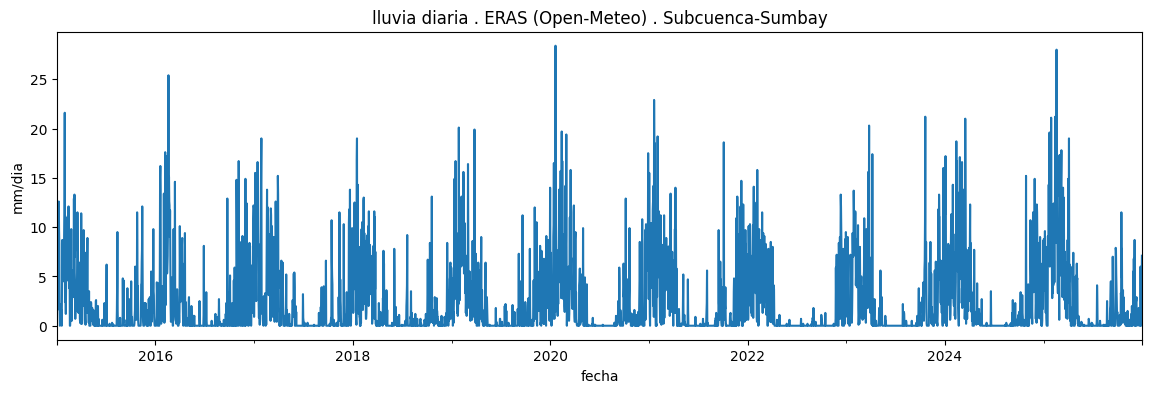

In [5]:
# visualizaciones
era5.plot(x="fecha", y="lluvia_mm", figsize=(14, 4), legend=False,
          title=f"lluvia diaria . ERAS (Open-Meteo) . {nombre}")
plt.ylabel("mm/dia")
plt.show()

In [6]:
# exportar datos
era5.to_csv(f'lluvia_era5_{nombre}.csv', index=False)
print('Guardado:', f'lluvia_era5_{nombre}.csv')

Guardado: lluvia_era5_Subcuenca-Sumbay.csv


In [7]:
def umbrales(serie, minimo=2):
    """
    calcula los umbrales de lluvia diaria(Fuerte, Severa, Extrema)
    utilizando percentiles basados unicamente en los dias de lluvia

    Parametros:
    - serie: Una serie de pandas con los registros de lluvia diaria en mm.
    - minimo: El umbral minimo en mm para considerar un dia como lluvioso (por defecto 2 mm).
    """
    # 1. Filtremos las serie para quedarnos solo con los dias donde realmente llovio significativamente
    dias_lluvia = serie[serie > minimo]

    # 2. Retornamos un DataFrame estructurado con los percentiles P90, P95 Y P99
    return pd.DataFrame({
        'categoria': ['Fuerte', 'Severa', 'Extrema'],
        'percentil': ['P90', 'P95', 'P99'],
        # .quantile([0.90, 0.95, 0.99]) calcula los valores correspondientes a esos percentiles.
        # .round(1) redondea los resultados a un solo decimal para mayor claridad.
        'umbral': dias_lluvia.quantile([0.9, 0.95, 0.99]).round(1).values,
})

tabla_era5 = umbrales(era5['lluvia_mm'])
tabla_era5

,categoria,percentil,umbral
0,Fuerte,P90,12.2
1,Severa,P95,14.8
2,Extrema,P99,19.6


In [8]:
# Aplicamos la funcion 'umbrales' a los datos de lluvia descargados para "Subcuenca del rio Sumbay"
resultados_umbrales = umbrales(era5['lluvia_mm'])
resultados_umbrales

,categoria,percentil,umbral
0,Fuerte,P90,12.2
1,Severa,P95,14.8
2,Extrema,P99,19.6


In [9]:
#  Un percentil, solo es un umbral, es el valor minimo donde el umbral,
# es el valor minimo donde el umbral se cumple, en este caso extremo
era5.nlargest(10, 'lluvia_mm').reset_index(drop=True)

,fecha,lluvia_mm
0,2020-01-21,28.4
1,2025-02-18,28.0
2,2016-02-18,25.4
3,2021-01-20,22.9
4,2015-01-30,21.6
5,2023-10-21,21.2
6,2025-02-13,21.2
7,2025-01-29,21.1
8,2024-03-17,21.0
9,2023-03-27,20.3


In [10]:
# lo mismo para Chirps desde GEE
import ee
import geemap

try:
    ee.Initialize()
except Exception:
    ee.Authenticate()
    ee.Initialize(project='catie-cuencas-miguel') # <- Nombre de mi proyecto propio de GEE

In [11]:
punto = ee.Geometry.Point([lon, lat]) # los parametros de la Subcuenca del rio Sumbay

chirps = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
          .filterDate(inicio, fin)
          .select('precipitation'))
def valor_en_punto(imagen):
    valor = imagen.reduceRegion(reducer=ee.Reducer.first(), geometry=punto, scale=5566)
    return ee.Feature(None, {'timestamp_ms': imagen.get('system:time_start'),
                             'lluvia_mm': valor.get('precipitation')})

table_gee = geemap.ee_to_df(ee.FeatureCollection(chirps.map(valor_en_punto)))

chirps_df = pd.DataFrame({
    'fecha': pd.to_datetime(table_gee['timestamp_ms'], unit='ms'),
    'lluvia_mm': pd.to_numeric(table_gee['lluvia_mm']),
}).dropna().sort_values('fecha').reset_index(drop=True)

chirps_df.to_csv(f'lluvia_chirps_{nombre}.csv', index=False)
print(f'{len(chirps_df)} dias . guardado: lluvia_chirps_{nombre}.csv')
chirps_df

4291 dias . guardado: lluvia_chirps_Subcuenca-Sumbay.csv


,fecha,lluvia_mm
0,2015-01-01,2.296204
1,2015-01-02,2.296204
2,2015-01-03,2.296204
3,2015-01-04,11.481019
4,2015-01-05,2.296204
...,...,...
4286,2026-09-26,0.000000
4287,2026-09-27,0.000000
4288,2026-09-28,6.527447
4289,2026-09-29,0.000000


In [12]:
comparacion = tabla_era5[['categoria', 'percentil']].copy()
comparacion['ERA5_mm'] = tabla_era5['umbral']
comparacion['CHIRPS_mm'] = umbrales(chirps_df['lluvia_mm'])['umbral']
comparacion

,categoria,percentil,ERA5_mm,CHIRPS_mm
0,Fuerte,P90,12.2,9.6
1,Severa,P95,14.8,12.5
2,Extrema,P99,19.6,17.6


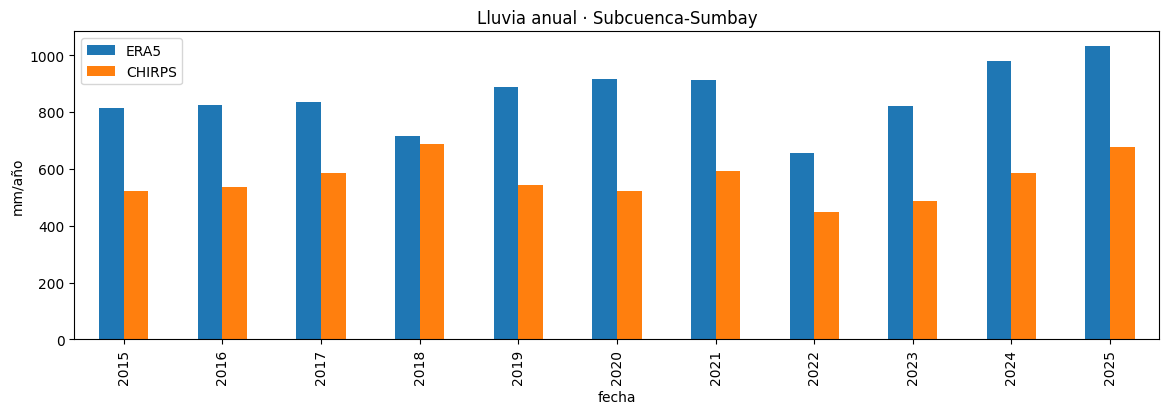

Sesgo diario (ERA5 - CHIRPS): 0.80 mm
Correlación diaria: 0.51


In [13]:
juntas = era5.merge(chirps_df, on='fecha', suffixes=('_era5', '_chirps'))

anual = juntas.groupby(juntas.fecha.dt.year)[['lluvia_mm_era5', 'lluvia_mm_chirps']].sum()
anual.columns = ['ERA5', 'CHIRPS']
anual.plot(kind='bar', figsize=(14, 4), title=f'Lluvia anual · {nombre}')
plt.ylabel('mm/año')
plt.show()

sesgo = (juntas['lluvia_mm_era5'] - juntas['lluvia_mm_chirps']).mean()
corr = juntas['lluvia_mm_era5'].corr(juntas['lluvia_mm_chirps'])
print(f'Sesgo diario (ERA5 - CHIRPS): {sesgo:.2f} mm')
print(f'Correlación diaria: {corr:.2f}')

comparacion.to_csv(f'umbrales_{nombre}.csv', index=False)

Area de la cuenca: 190.3


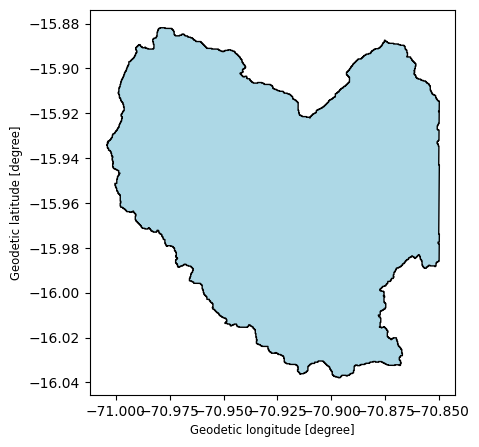

In [14]:
import geopandas as gpd
import numpy as np

url_cuenca = "https://raw.githubusercontent.com/lazaroninamiguel-dot/mchv502-cuencas/refs/heads/main/T03_delimitacion/resultados/T03_micro_cuenca_imata_chili.geojson" # Cuenca propia
cuenca = gpd.read_file(url_cuenca).to_crs(4326)
poligono = cuenca.dissolve().geometry.iloc[0] # Corregido de floc(0) a iloc[0]

area_km2 = cuenca.to_crs(cuenca.estimate_utm_crs()).area.sum() / 1e6
print(f'Area de la cuenca: {area_km2:.1f}')
cuenca.plot(edgecolor= 'black', facecolor='lightblue', figsize=(5, 5))
plt.show()

19 puntos dentro de la cuenca


,lat,lon
2,-16.0227,-70.9294
3,-16.0227,-70.8994
4,-16.0227,-70.8694
6,-15.9927,-70.9594
7,-15.9927,-70.9294
8,-15.9927,-70.8994
10,-15.9627,-70.9894
11,-15.9627,-70.9594
12,-15.9627,-70.9294
13,-15.9627,-70.8994


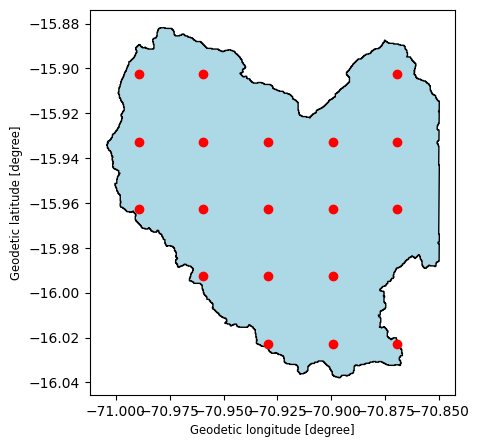

In [15]:
# si no tenemos estaciones podemos simular una estacion basado en un registro historico simulado

# Asegurar que la variable nombre exista en el entorno
if 'nombre' not in globals():
    nombre = "Subcuenca-Sumbay"

paso = 0.03 # grados que tan espaciados estan

xmin, ymin, xmax, ymax = cuenca.total_bounds
xs, ys = np.meshgrid(np.arange(xmin + paso/ 2, xmax, paso),
                     np.arange(ymin + paso / 2, ymax, paso))
malla = gpd.GeoDataFrame(geometry=gpd.points_from_xy(xs.ravel(), ys.ravel()), crs=4326)

# Filtramos los puntos que están dentro de la cuenca usando sjoin
puntos = gpd.sjoin(malla, cuenca, predicate='within')

if len(puntos) == 0: # cuenca mas pequeña que la malla: seusa un punto interior
    puntos = gpd.GeoDataFrame(geometry=[poligono.representative_point()], crs=4326)

puntos['lat'] = puntos.geometry.y.round(4)
puntos['lon'] = puntos.geometry.x.round(4)
print(f'{len(puntos)} puntos dentro de la cuenca')

ax = cuenca.plot(edgecolor='black', facecolor='lightblue', figsize=(5, 5))
puntos.plot(ax=ax, color ='red')

puntos.to_file(f'puntos_cuenca_{nombre}.geojson') # para revisar en QGIS o geolibre.app
puntos[['lat','lon']]

In [16]:
import time
import pandas as pd
import requests

def serie_open_meteo(lat, lon):
    """lluvia diaria de Open-Meteo en una coordenada (la misma consulta del paso 1)."""
    parametro = {
        "latitude": lat,
        "longitude": lon,
        "start_date": inicio,
        "end_date": fin,
        "daily": "precipitation_sum",
        "timezone": "auto"
    }
    respuesta = requests.get("https://archive-api.open-meteo.com/v1/archive", params=parametro, timeout=120)

    if respuesta.status_code != 200:
        print(f'\nError de API ({respuesta.status_code}) para lat: {lat}, lon: {lon}')
        print('Respuesta:', respuesta.text)
        return None

    datos = respuesta.json()
    datos_diarios = datos.get('daily', {})
    return pd.Series(datos_diarios.get('precipitation_sum', []),
                     index=pd.to_datetime(datos_diarios.get('time', [])))

# El bucle de ejecución debe estar fuera de la definición de la función
series = {}
for i, fila in puntos.iterrows():
    serie = serie_open_meteo(fila['lat'], fila['lon'])
    if serie is not None:
        series[f'punto_{i+1}'] = serie
        print(f'punto_{i+1} listo')
    else:
        print(f'punto_{i+1} falló')
    time.sleep(1.5)  # pausa para evitar el límite de tasa de la API

tabla_puntos = pd.DataFrame(series)
tabla_puntos.head()

punto_3 listo
punto_4 listo
punto_5 listo
punto_7 listo
punto_8 listo
punto_9 listo
punto_11 listo
punto_12 listo
punto_13 listo
punto_14 listo
punto_15 listo
punto_16 listo
punto_17 listo
punto_18 listo
punto_19 listo
punto_20 listo
punto_21 listo
punto_22 listo
punto_25 listo


,punto_3,punto_4,punto_5,punto_7,punto_8,punto_9,punto_11,punto_12,punto_13,punto_14,punto_15,punto_16,punto_17,punto_18,punto_19,punto_20,punto_21,punto_22,punto_25
2015-01-01,0.2,0.2,4.1,0.2,0.2,0.2,0.2,0.2,0.2,0.2,4.1,0.2,0.2,0.2,0.2,4.1,0.2,0.2,4.1
2015-01-02,8.0,8.0,9.5,8.0,8.0,8.0,8.0,8.0,8.0,8.0,9.5,8.0,8.0,8.0,8.0,9.5,8.0,8.0,9.5
2015-01-03,1.6,1.6,2.7,1.6,1.6,1.6,1.6,1.6,1.6,1.6,2.7,1.6,1.6,1.6,1.6,2.7,1.6,1.6,2.7
2015-01-04,8.2,8.2,6.9,8.2,8.2,8.2,8.2,8.2,8.2,8.2,6.9,8.2,8.2,8.2,8.2,6.9,8.2,8.2,6.9
2015-01-05,7.7,7.7,16.4,7.7,7.7,7.7,7.7,7.7,7.7,7.7,16.4,7.7,7.7,7.7,7.7,16.4,7.7,7.7,16.4


In [17]:
cuenca_era5 = pd.DataFrame({
    'fecha': tabla_puntos.index,
    'lluvia_mm': tabla_puntos.mean(axis=1).round(2).values, # ojo la funcion mean promedia

}).dropna()

cuenca_era5.to_csv(f'lluvia_cuenca_era5_{nombre}.csv', index=False)
print('guardado:', f'lluvia_cuenca_era5_{nombre}.csv')
cuenca_era5

guardado: lluvia_cuenca_era5_Subcuenca-Sumbay.csv


,fecha,lluvia_mm
0,2015-01-01,1.02
1,2015-01-02,8.32
2,2015-01-03,1.83
3,2015-01-04,7.93
4,2015-01-05,9.53
...,...,...
4327,2026-11-06,15.58
4328,2026-11-07,0.88
4329,2026-11-08,8.55
4330,2026-11-09,9.83
